In [1]:

# Dependencias necesarias.
%pip -q install pandas scikit-learn matplotlib openpyxl



## 1. Importe de librerías


In [2]:

from pathlib import Path
from io import BytesIO
import warnings
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
)

RANDOM_STATE = 42
N_INIT = 10
OUT = Path('/content/resultados_ML_No_Supervisado')
OUT.mkdir(parents=True, exist_ok=True)
print('Carpeta de resultados:', OUT)


Carpeta de resultados: /content/resultados_ML_No_Supervisado



## 2. Carga del dataset



In [3]:

from google.colab import files

uploaded = files.upload()
excel_names = [name for name in uploaded if name.lower().endswith(('.xlsx', '.xls'))]
if not excel_names:
    raise ValueError('No se cargó ningún archivo Excel. Vuelve a ejecutar esta celda y selecciona DATASET_INmuebles.xlsx.')

DATASET_NAME = next((name for name in excel_names if 'dataset' in name.lower()), excel_names[0])
print('Archivo seleccionado:', DATASET_NAME)
raw = pd.read_excel(BytesIO(uploaded[DATASET_NAME]), sheet_name='Inmuebles_Arriendo')
print('Dimensiones originales:', raw.shape)
print('Columnas originales:', list(raw.columns))
display(raw.head())


Saving DATASET_INmuebles.xlsx to DATASET_INmuebles.xlsx
Archivo seleccionado: DATASET_INmuebles.xlsx
Dimensiones originales: (1000, 10)
Columnas originales: ['Inmueble', 'Área m²', 'Habitaciones', 'Estrato', 'Precio arriendo', 'Baños', 'Antig[uedad', 'Localidad', 'Tipo Inmueble', 'Estrato.1']


,Inmueble,Área m²,Habitaciones,Estrato,Precio arriendo,Baños,Antig[uedad,Localidad,Tipo Inmueble,Estrato.1
0,I1,69,2,2,1413951,2,11,Suba,Apto,2
1,I2,39,1,2,1006165,2,10,Chapinero,Casa,3
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio,4
3,I4,62,3,4,3678698,1,12,Suba,Apto,3
4,I5,58,1,3,875729,1,12,Chapinero,Casa,4



## 3. Prepararción de los datos

Se usan las ocho características definidas.


In [6]:
df = raw.iloc[:, :9].copy()
df.columns = expected_names
if raw.shape[1] > 9:
    print('se excluye la columna extra', repr(raw.columns[9]),
          'porque repite el nombre Estrato')

num_cols = ['Area_m2', 'Habitaciones', 'Estrato', 'Precio_arriendo', 'Banos', 'Antiguedad_anios']
cat_cols = ['Localidad', 'Tipo_inmueble']
features = df[num_cols + cat_cols].copy()

missing = features.isna().sum()
if int(missing.sum()) > 0:
    raise ValueError('Hay valores faltantes en variables seleccionadas:\n' + str(missing[missing > 0]))

# Estandarizar numéricas y codificar categóricas con one-hot encoding.
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:  # Compatibilidad con versiones antiguas de scikit-learn
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', encoder, cat_cols),
    ],
    remainder='drop',
)
X = preprocessor.fit_transform(features)
feature_names = preprocessor.get_feature_names_out()

print('Registros:', len(df))
print('Valores faltantes en variables usadas:', int(features.isna().sum().sum()))
print('Variables originales usadas:', len(num_cols) + len(cat_cols))
print('Columnas numéricas después de escalar/codificar:', X.shape[1])
print('Variables transformadas:', list(feature_names))

descriptive = df[num_cols].describe().T.reset_index().rename(columns={'index': 'Variable'})
descriptive.to_csv(OUT / 'estadisticas_descriptivas.csv', index=False, encoding='utf-8-sig')


se excluye la columna extra 'Estrato.1' porque repite el nombre Estrato
Registros: 1000
Valores faltantes en variables usadas: 0
Variables originales usadas: 8
Columnas numéricas después de escalar/codificar: 12
Variables transformadas: ['num__Area_m2', 'num__Habitaciones', 'num__Estrato', 'num__Precio_arriendo', 'num__Banos', 'num__Antiguedad_anios', 'cat__Localidad_Chapinero', 'cat__Localidad_Suba', 'cat__Localidad_Usaquén', 'cat__Tipo_inmueble_ApartaEstudio', 'cat__Tipo_inmueble_Apto', 'cat__Tipo_inmueble_Casa']



## 4. Entrenamiento y comparación K-Means con K = 2, 3 y 4

El número K indica cuántos grupos se solicitan al algoritmo. Para comparar las configuraciones se utiliza el coeficiente *silhouette*: cuanto mayor sea, mejor separación relativa entre grupos


In [7]:

metrics_rows = []
summary_rows = []
labels_by_k = {}

for k in (2, 3, 4):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
    labels = model.fit_predict(X)
    labels_by_k[k] = labels
    df[f'Cluster_K{k}'] = labels
    metrics_rows.append({
        'n_clusters': k,
        'silhouette': float(silhouette_score(X, labels)),
        'inercia': float(model.inertia_),
        'calinski_harabasz': float(calinski_harabasz_score(X, labels)),
        'davies_bouldin': float(davies_bouldin_score(X, labels)),
        'tamano_min_cluster': int(pd.Series(labels).value_counts().min()),
        'tamano_max_cluster': int(pd.Series(labels).value_counts().max()),
    })
    for c in range(k):
        part = df.loc[labels == c]
        mode_loc = part['Localidad'].mode().iloc[0]
        mode_type = part['Tipo_inmueble'].mode().iloc[0]
        summary_rows.append({
            'n_clusters': k,
            'cluster': c,
            'cantidad': int(len(part)),
            'porcentaje': 100 * len(part) / len(df),
            'area_media_m2': part['Area_m2'].mean(),
            'habitaciones_media': part['Habitaciones'].mean(),
            'estrato_medio': part['Estrato'].mean(),
            'precio_medio_arriendo': part['Precio_arriendo'].mean(),
            'banos_media': part['Banos'].mean(),
            'antiguedad_media_anios': part['Antiguedad_anios'].mean(),
            'localidad_mas_frecuente': mode_loc,
            'porcentaje_localidad_mas_frecuente': 100 * (part['Localidad'] == mode_loc).mean(),
            'tipo_mas_frecuente': mode_type,
            'porcentaje_tipo_mas_frecuente': 100 * (part['Tipo_inmueble'] == mode_type).mean(),
        })

metrics_df = pd.DataFrame(metrics_rows)
summary_df = pd.DataFrame(summary_rows)
metrics_df.to_csv(OUT / 'comparacion_kmeans_2_3_4.csv', index=False, encoding='utf-8-sig', float_format='%.6f')
summary_df.to_csv(OUT / 'perfiles_clusters.csv', index=False, encoding='utf-8-sig', float_format='%.4f')

display(metrics_df.round(4))
print('Tamaño de cada clúster por K:')
for k in (2, 3, 4):
    print(f'K={k}:', pd.Series(labels_by_k[k]).value_counts().sort_index().to_dict())


,n_clusters,silhouette,inercia,calinski_harabasz,davies_bouldin,tamano_min_cluster,tamano_max_cluster
0,2,0.3503,4441.9218,649.6349,1.2067,382,618
1,3,0.2555,3824.4520,457.3666,1.5387,292,382
2,4,0.2222,3440.6826,375.6114,1.8506,188,326


Tamaño de cada clúster por K:
K=2: {0: 618, 1: 382}
K=3: {0: 326, 1: 382, 2: 292}
K=4: {0: 326, 1: 188, 2: 194, 3: 292}



## 5. Aplicación PCA y comparación de las asignaciones

PCA reduce la matriz preprocesada a dos componentes para facilitar la visualización. Los dos componentes conservan parte de la variabilidad, no toda; por eso se compara K-Means sobre las características procesadas con K-Means usando solamente PC1 y PC2


In [8]:

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)

df_pca = pd.DataFrame({
    'ID_inmueble': df['ID_inmueble'],
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'Cluster_K2': labels_by_k[2],
    'Cluster_K3': labels_by_k[3],
    'Cluster_K4': labels_by_k[4],
})
labels_pca_by_k = {}
comparison_rows = []
for k in (2, 3, 4):
    model_pca = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
    labels_pca = model_pca.fit_predict(X_pca)
    labels_pca_by_k[k] = labels_pca
    df_pca[f'Cluster_PCA_K{k}'] = labels_pca
    comparison_rows.append({
        'n_clusters': k,
        'silhouette_datos_preprocesados': float(silhouette_score(X, labels_by_k[k])),
        'silhouette_solo_PCA2': float(silhouette_score(X_pca, labels_pca)),
        'ARI_misma_asignacion': float(adjusted_rand_score(labels_by_k[k], labels_pca)),
        'nota': 'ARI=1 indica mismas particiones, sin importar los números de etiqueta asignados a cada grupo.'
    })
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(OUT / 'comparacion_kmeans_vs_pca.csv', index=False, encoding='utf-8-sig', float_format='%.6f')
df_pca.to_csv(OUT / 'coordenadas_pca_y_clusters.csv', index=False, encoding='utf-8-sig', float_format='%.6f')

df.to_csv(OUT / 'dataset_con_clusters.csv', index=False, encoding='utf-8-sig')
with open(OUT / 'dimensiones_y_variables.txt', 'w', encoding='utf-8') as f:
    f.write(f'Registros: {len(df)}\n')
    f.write(f'Variables documentadas originales usadas: {len(num_cols) + len(cat_cols)}\n')
    f.write('ID excluido de los cálculos: sí\n')
    f.write(f'Columna extra duplicada excluida: {raw.columns[9] if raw.shape[1] > 9 else "no existe"}\n')
    f.write(f'Dimensiones después de escalar y codificar: {X.shape[1]}\n')
    f.write(f'Dimensiones después de PCA: {X_pca.shape[1]}\n')
    f.write('Columnas modeladas tras preprocesamiento:\n')
    for name in feature_names:
        f.write(f'- {name}\n')
    f.write(f'PC1 varianza explicada: {pca.explained_variance_ratio_[0]*100:.4f}%\n')
    f.write(f'PC2 varianza explicada: {pca.explained_variance_ratio_[1]*100:.4f}%\n')
    f.write(f'Varianza acumulada PC1+PC2: {pca.explained_variance_ratio_.sum()*100:.4f}%\n')

display(comparison_df.round(4))
print('Varianza de PC1: {:.2f}%'.format(pca.explained_variance_ratio_[0]*100))
print('Varianza de PC2: {:.2f}%'.format(pca.explained_variance_ratio_[1]*100))
print('Varianza acumulada: {:.2f}%'.format(pca.explained_variance_ratio_.sum()*100))


,n_clusters,silhouette_datos_preprocesados,silhouette_solo_PCA2,ARI_misma_asignacion,nota
0,2,0.3503,0.5706,1.0000,"ARI=1 indica mismas particiones, sin importar ..."
1,3,0.2555,0.4498,0.6796,"ARI=1 indica mismas particiones, sin importar ..."
2,4,0.2222,0.3752,0.4824,"ARI=1 indica mismas particiones, sin importar ..."


Varianza de PC1: 46.54%
Varianza de PC2: 13.75%
Varianza acumulada: 60.29%



## 6. Gráficos y evidencias


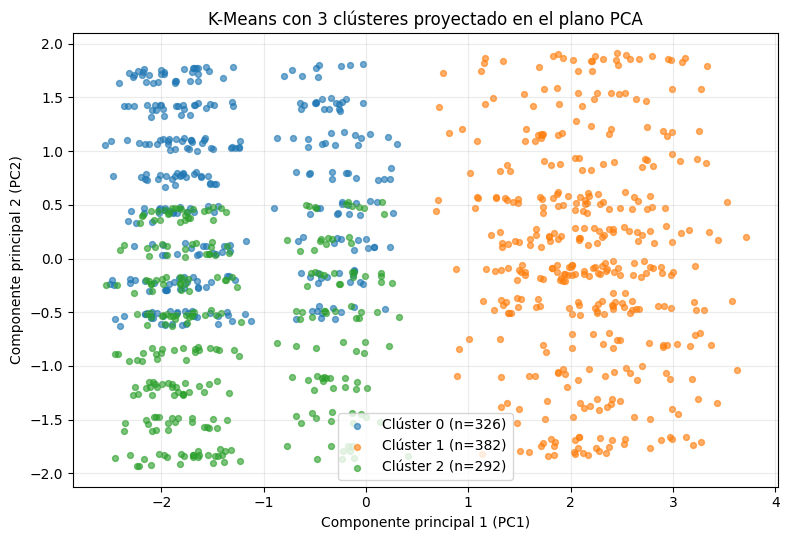

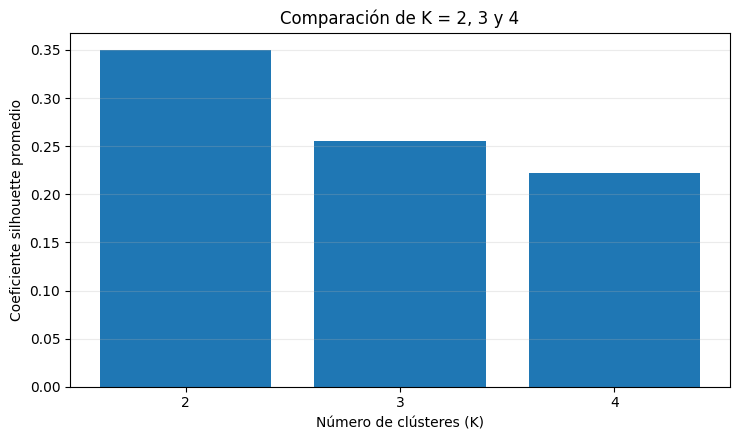

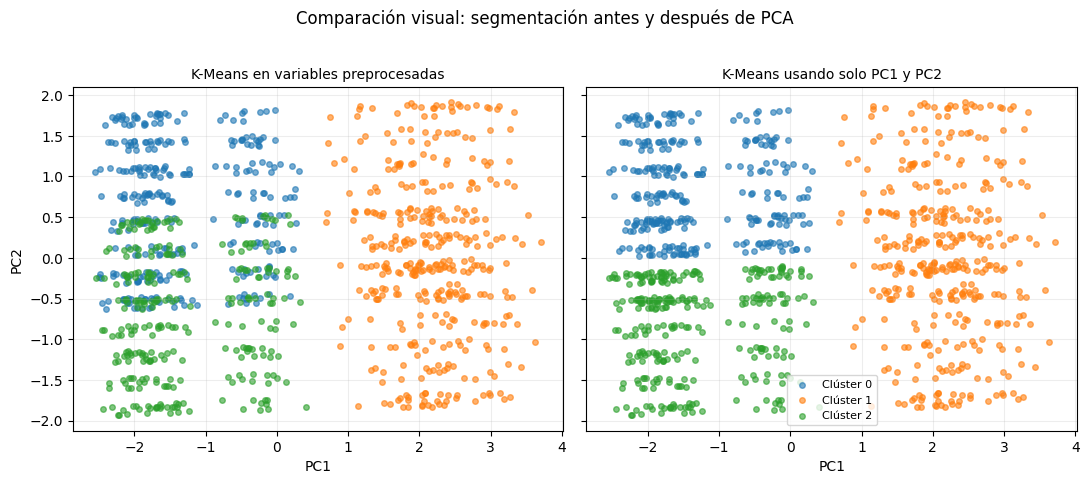

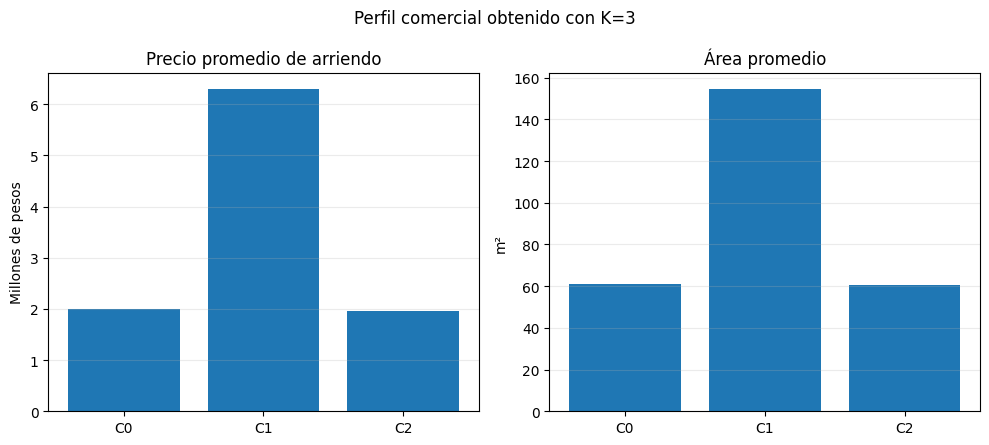

In [9]:

# Figura 1: K=3 proyectado sobre PC1 y PC2.
plt.figure(figsize=(8, 5.5))
lab = labels_by_k[3]
for c in sorted(set(lab)):
    ix = lab == c
    plt.scatter(X_pca[ix, 0], X_pca[ix, 1], s=18, alpha=0.62, label=f'Clúster {c} (n={ix.sum()})')
plt.xlabel('Componente principal 1 (PC1)')
plt.ylabel('Componente principal 2 (PC2)')
plt.title('K-Means con 3 clústeres proyectado en el plano PCA')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUT / '01_kmeans3_proyectado_PCA.png', dpi=180)
plt.show()
plt.close()

# Figura 2: comparación de silhouette.
plt.figure(figsize=(7.5, 4.5))
plt.bar(metrics_df['n_clusters'].astype(str), metrics_df['silhouette'])
plt.xlabel('Número de clústeres (K)')
plt.ylabel('Coeficiente silhouette promedio')
plt.title('Comparación de K = 2, 3 y 4')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig(OUT / '02_comparacion_silhouette.png', dpi=180)
plt.show()
plt.close()

# Figura 3: segmentación completa frente a segmentación usando solo PCA.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.7), sharex=True, sharey=True)
for ax, labs, title in [
    (axes[0], labels_by_k[3], 'K-Means en variables preprocesadas'),
    (axes[1], labels_pca_by_k[3], 'K-Means usando solo PC1 y PC2'),
]:
    for c in sorted(set(labs)):
        ix = labs == c
        ax.scatter(X_pca[ix, 0], X_pca[ix, 1], s=16, alpha=0.6, label=f'Clúster {c}')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('PC1')
    ax.grid(True, alpha=0.22)
axes[0].set_ylabel('PC2')
axes[1].legend(loc='best', fontsize=8)
fig.suptitle('Comparación visual: segmentación antes y después de PCA', y=1.02)
fig.tight_layout()
fig.savefig(OUT / '03_comparacion_clusters_antes_despues_PCA.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

# Figura 4: perfiles comerciales con K=3.
prof3 = summary_df[summary_df['n_clusters'] == 3].sort_values('cluster')
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].bar([f'C{c}' for c in prof3['cluster']], prof3['precio_medio_arriendo'] / 1_000_000)
axes[0].set_title('Precio promedio de arriendo')
axes[0].set_ylabel('Millones de pesos')
axes[0].grid(axis='y', alpha=0.25)
axes[1].bar([f'C{c}' for c in prof3['cluster']], prof3['area_media_m2'])
axes[1].set_title('Área promedio')
axes[1].set_ylabel('m²')
axes[1].grid(axis='y', alpha=0.25)
fig.suptitle('Perfil comercial obtenido con K=3')
fig.tight_layout()
fig.savefig(OUT / '04_perfiles_comerciales_k3.png', dpi=180)
plt.show()
plt.close(fig)



## 7. Tablas


In [10]:

print('=== ESTADÍSTICAS DESCRIPTIVAS ===')
display(descriptive.round(2))
print('=== COMPARACIÓN K-MEANS ===')
display(metrics_df.round(4))
print('=== PERFILES DE CLÚSTERES CON K=3 ===')
display(prof3.round(2))
print('=== K-MEANS COMPLETO FRENTE A PCA ===')
display(comparison_df.round(4))
print('=== ASIGNACIÓN DE CLÚSTERES (primeras 10 filas) ===')
display(df.head(10))


=== ESTADÍSTICAS DESCRIPTIVAS ===


,Variable,count,mean,std,min,25%,50%,75%,max
0,Area_m2,1000.0,96.73,54.10,30.0,55.00,80.5,135.0,220.0
1,Habitaciones,1000.0,2.66,1.28,1.0,2.00,2.0,4.0,5.0
2,Estrato,1000.0,3.96,1.43,2.0,3.00,4.0,5.0,6.0
3,Precio_arriendo,1000.0,3633286.68,2438534.26,702480.0,1644060.25,2930804.5,5394807.0,8988836.0
4,Banos,1000.0,1.48,0.50,1.0,1.00,1.0,2.0,2.0
5,Antiguedad_anios,1000.0,8.46,2.35,5.0,6.00,8.5,10.0,12.0


=== COMPARACIÓN K-MEANS ===


,n_clusters,silhouette,inercia,calinski_harabasz,davies_bouldin,tamano_min_cluster,tamano_max_cluster
0,2,0.3503,4441.9218,649.6349,1.2067,382,618
1,3,0.2555,3824.4520,457.3666,1.5387,292,382
2,4,0.2222,3440.6826,375.6114,1.8506,188,326


=== PERFILES DE CLÚSTERES CON K=3 ===


,n_clusters,cluster,cantidad,porcentaje,area_media_m2,habitaciones_media,estrato_medio,precio_medio_arriendo,banos_media,antiguedad_media_anios,localidad_mas_frecuente,porcentaje_localidad_mas_frecuente,tipo_mas_frecuente,porcentaje_tipo_mas_frecuente
2,3,0,326,32.6,61.25,1.83,2.99,2000101.25,1.00,8.56,Suba,34.97,Apto,34.97
3,3,1,382,38.2,154.56,4.01,5.53,6300711.57,1.49,8.35,Usaquén,38.48,ApartaEstudio,38.48
4,3,2,292,29.2,60.68,1.83,2.98,1967061.15,2.00,8.48,Chapinero,35.96,Casa,35.96


=== K-MEANS COMPLETO FRENTE A PCA ===


,n_clusters,silhouette_datos_preprocesados,silhouette_solo_PCA2,ARI_misma_asignacion,nota
0,2,0.3503,0.5706,1.0000,"ARI=1 indica mismas particiones, sin importar ..."
1,3,0.2555,0.4498,0.6796,"ARI=1 indica mismas particiones, sin importar ..."
2,4,0.2222,0.3752,0.4824,"ARI=1 indica mismas particiones, sin importar ..."


=== ASIGNACIÓN DE CLÚSTERES (primeras 10 filas) ===


,ID_inmueble,Area_m2,Habitaciones,Estrato,Precio_arriendo,Banos,Antiguedad_anios,Localidad,Tipo_inmueble,Cluster_K2,Cluster_K3,Cluster_K4
0,I1,69,2,2,1413951,2,11,Suba,Apto,0,2,3
1,I2,39,1,2,1006165,2,10,Chapinero,Casa,0,2,3
2,I3,142,5,5,8570904,1,8,Usaquén,ApartaEstudio,1,1,2
3,I4,62,3,4,3678698,1,12,Suba,Apto,0,0,0
4,I5,58,1,3,875729,1,12,Chapinero,Casa,0,0,0
5,I6,76,3,4,2836207,1,8,Usaquén,ApartaEstudio,0,0,0
6,I7,80,2,4,3808969,2,7,Suba,Apto,0,2,3
7,I8,204,4,6,8338969,1,12,Chapinero,Casa,1,1,2
8,I9,99,4,5,8336930,2,7,Usaquén,ApartaEstudio,1,1,1
9,I10,111,5,5,5758932,1,6,Suba,Apto,1,1,2
